# Auto.ru — фотографии и сведения об объявлениях

Используются `listings.jsonl`, последние снимки из `checkpoints/listings/` и фото из `images/<listing_id>/`. Незавершённая последняя строка JSONL после остановки парсера пропускается.

Выбираются разные объявления, затем по одному фото каждого. `PHOTO_INDEX = None` — случайный кадр; `0` — первый, `1` — второй. Если кадров меньше, берётся последний доступный. Под фотографиями доступны описания и структурированные поля в раскрывающихся блоках. Папки фото без записи объявления тоже доступны для просмотра.

Классов, рамок и масок повреждений в объявлениях нет. `SPLIT = "all"`. Фильтры: `BRAND_FILTER`, `ONLY_WITH_DESCRIPTION`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "autoru"
SPLIT = "all"
PHOTO_INDEX = None          # None = случайный кадр; 0 = первый
BRAND_FILTER = None         # Например, "Toyota"
ONLY_WITH_DESCRIPTION = False
N_IMAGES = 6
N_COLS = 3
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
from html import escape
from urllib.parse import urlsplit
from IPython.display import HTML, display


def load_dataset(root):
    records = {row["listing_id"]: row for row in read_jsonl(root / "listings.jsonl")}
    for path in sorted((root / "checkpoints" / "listings").glob("*.json")):
        row = json.loads(path.read_text(encoding="utf-8"))
        records[row["listing_id"]] = row
    for folder in sorted((root / "images").iterdir()):
        if folder.is_dir():
            records.setdefault(folder.name, {"listing_id": folder.name})
    samples = []
    for listing_id, row in records.items():
        photos = {
            root / photo["path"] for photo in row.get("photos", [])
            if (root / photo["path"]).is_file()
        }
        folder = root / "images" / listing_id
        if folder.is_dir():
            photos.update(path for path in folder.iterdir()
                          if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES)
        if not photos:
            continue
        vehicle = row.get("vehicle") or {}
        if BRAND_FILTER and str(vehicle.get("brand", "")).casefold() != BRAND_FILTER.casefold():
            continue
        if ONLY_WITH_DESCRIPTION and not str(row.get("description") or "").strip():
            continue
        price = row.get("price") or {}
        price_text = (
            f"{price['amount']:,} {price.get('currency') or ''}"
            if isinstance(price.get("amount"), (int, float)) else "Цена не указана"
        )
        paths = sorted(photos)
        samples.append({
            "image_path": paths[0], "photo_paths": paths, "file_name": paths[0].name,
            "split": "all", "task": "listing", "annotations": [], "metadata": row,
            "caption": f"{row.get('title') or listing_id}\n{price_text} · Фото: {len(paths)}",
        })
    return samples


def show_listing_details(selected):
    blocks = []
    for sample in selected:
        row = sample["metadata"]
        title = escape(str(row.get("title") or row["listing_id"]))
        description = escape(str(row.get("description") or "Описание отсутствует."))
        source = str(row.get("source_url") or "")
        link = (
            f'<a href="{escape(source, quote=True)}" target="_blank">Исходное объявление</a>'
            if urlsplit(source).scheme in {"http", "https"} else ""
        )
        structured = {key: row.get(key) for key in (
            "listing_id", "source_url", "price", "vehicle", "seller", "location",
            "published_at", "features", "attributes",
        )}
        metadata = escape(json.dumps(structured, ensure_ascii=False, indent=2))
        blocks.append(
            f'<details style="margin:12px 0"><summary><b>{title}</b> — описание и данные</summary>'
            f'<p>{link}</p><div style="white-space:pre-wrap">{description}</div>'
            f'<details><summary>Структурированные поля</summary><pre>{metadata}</pre></details></details>'
        )
    display(HTML("".join(blocks)))


dataset = load_dataset(DATASET_ROOT)
summary = summarize(dataset)
print("Фотографий в доступных объявлениях:", sum(len(sample["photo_paths"]) for sample in dataset))


Записей: 530; изображения отсутствуют: 0
Выборки: {'all': 530}
Фотографий в доступных объявлениях: 13017


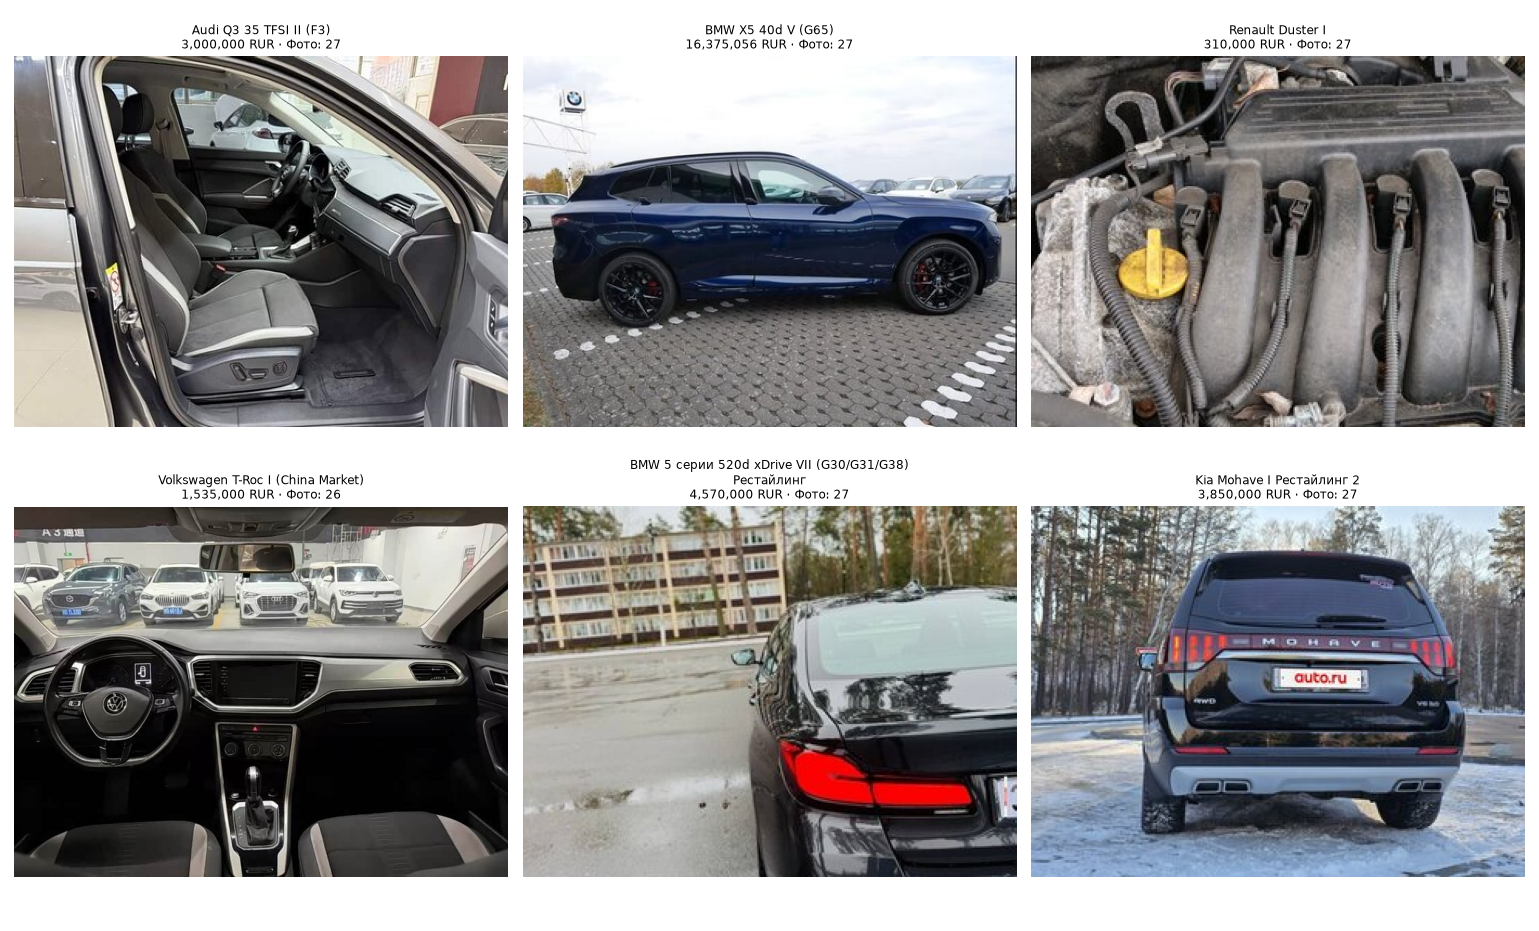

<Listing descriptions and structured metadata>

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED, photo_index=PHOTO_INDEX,
)

show_listing_details(selected_samples)
